MODELO LINEAL SIMPLE
Cantidad de mediciones: 1503
Media del ruido: 124.835943 dB
Intercepto b0: 127.303737592 dB
Pendiente b1: -0.000854979013 dB/Hz
Recta: ŷ = 127.303738 -0.000854979013 · x

DESCOMPOSICIÓN DE LA VARIABILIDAD
        Componente  Suma de cuadrados (dB²)
       Total (STC)             71482.377701
   Explicada (SCR)             10912.171478
No explicada (SCE)             60570.206223

STC:       71482.377701
SCR + SCE: 71482.377701

VARIANZA ESTIMADA Y R²
Grados de libertad: 1501
Varianza estimada: 40.353235 dB²
R²: 0.152655
Variabilidad explicada: 15.27%
Variabilidad no explicada: 84.73%


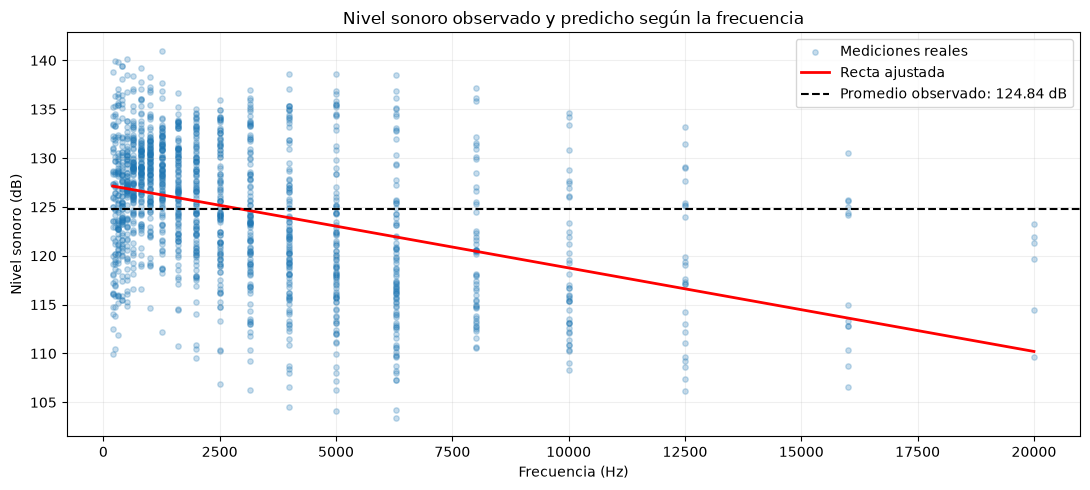

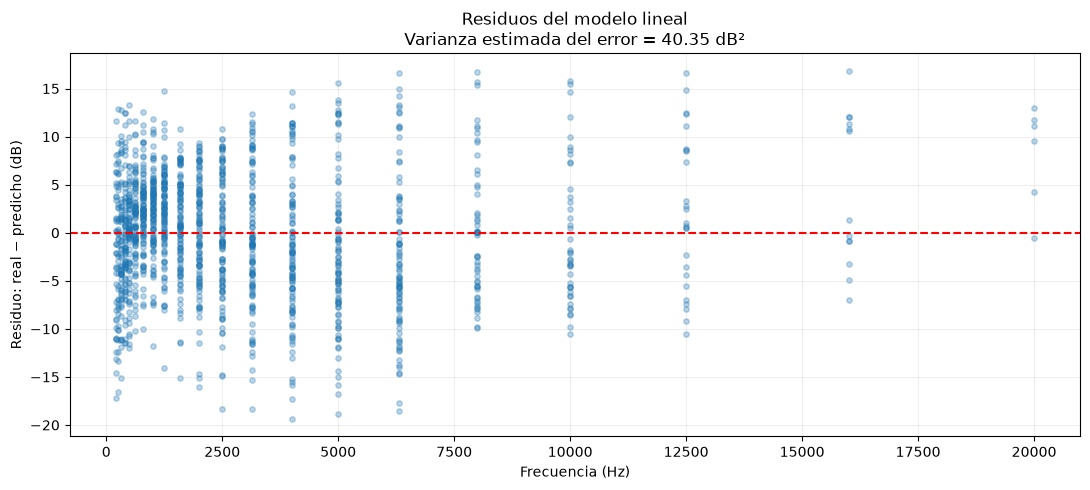

Varianza estimada: 40.353235 dB²
Desviación residual: 6.35 dB
R²: 0.152655
Variabilidad explicada: 15.27%
Variabilidad sin explicar: 84.73%


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. CARGA DE DATOS
# ============================================================

datos = pd.read_csv(
    "../dataset/airfoil_self_noise.dat",
    sep=r"\s+",
    header=None,
    names=[
        "frequency", "angle", "chord_length",
        "velocity", "displacement", "sound_level"
    ]
)

x = datos["frequency"].to_numpy()
y = datos["sound_level"].to_numpy()

n = len(y)
x_media = x.mean()
y_media = y.mean()

# ============================================================
# 2. RECTA POR MÍNIMOS CUADRADOS
# ============================================================

Sxx = np.sum((x - x_media)**2)
Sxy = np.sum((x - x_media) * (y - y_media))

b1 = Sxy / Sxx
b0 = y_media - b1 * x_media

y_estimado = b0 + b1 * x
residuos = y - y_estimado

print("MODELO LINEAL SIMPLE")
print(f"Cantidad de mediciones: {n}")
print(f"Media del ruido: {y_media:.6f} dB")
print(f"Intercepto b0: {b0:.9f} dB")
print(f"Pendiente b1: {b1:.12f} dB/Hz")
print(f"Recta: ŷ = {b0:.6f} {b1:+.12f} · x")

# ============================================================
# 3. B.1: DESCOMPOSICIÓN DE LA VARIABILIDAD
# ============================================================

# Total: valores reales respecto del promedio
STC = np.sum((y - y_media)**2)

# Explicada: predicciones respecto del promedio
SCR = np.sum((y_estimado - y_media)**2)

# No explicada: valores reales respecto de sus predicciones
SCE = np.sum(residuos**2)

tabla = pd.DataFrame({
    "Componente": [
        "Total (STC)",
        "Explicada (SCR)",
        "No explicada (SCE)"
    ],
    "Suma de cuadrados (dB²)": [STC, SCR, SCE]
})

print("\nDESCOMPOSICIÓN DE LA VARIABILIDAD")
print(tabla.to_string(index=False, float_format=lambda valor: f"{valor:.6f}"))

print(f"\nSTC:       {STC:.6f}")
print(f"SCR + SCE: {SCR + SCE:.6f}")

# ============================================================
# 4. B.1: VARIANZA ESTIMADA Y R²
# ============================================================

varianza_estimada = SCE / (n - 2)
R2 = 1 - SCE / STC

porcentaje_explicado = 100 * R2
porcentaje_no_explicado = 100 * SCE / STC

print("\nVARIANZA ESTIMADA Y R²")
print(f"Grados de libertad: {n - 2}")
print(f"Varianza estimada: {varianza_estimada:.6f} dB²")
print(f"R²: {R2:.6f}")
print(f"Variabilidad explicada: {porcentaje_explicado:.2f}%")
print(f"Variabilidad no explicada: {porcentaje_no_explicado:.2f}%")

# ============================================================
# 5. GRÁFICO: DATOS, RECTA Y PROMEDIO
# ============================================================

orden = np.argsort(x)

fig, ax = plt.subplots(figsize=(11, 5))

ax.scatter(
    x, y, alpha=0.25, s=15,
    label="Mediciones reales"
)
ax.plot(
    x[orden], y_estimado[orden],
    color="red", linewidth=2,
    label="Recta ajustada"
)
ax.axhline(
    y_media, color="black", linestyle="--",
    label=f"Promedio observado: {y_media:.2f} dB"
)

ax.set_xlabel("Frecuencia (Hz)")
ax.set_ylabel("Nivel sonoro (dB)")
ax.set_title("Nivel sonoro observado y predicho según la frecuencia")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()

# ============================================================
# 6. GRÁFICO: RESIDUOS
# ============================================================

fig, ax = plt.subplots(figsize=(11, 5))

ax.scatter(x, residuos, alpha=0.3, s=15)
ax.axhline(0, color="red", linestyle="--")

ax.set_xlabel("Frecuencia (Hz)")
ax.set_ylabel("Residuo: real − predicho (dB)")
ax.set_title(
    "Residuos del modelo lineal\n"
    f"Varianza estimada del error = {varianza_estimada:.2f} dB²"
)
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()

# Estimación de la varianza del error
varianza_estimada = SCE / (n - 2)

# Raíz de la varianza: dispersión residual expresada en dB
desviacion_residual = np.sqrt(varianza_estimada)

# Proporción de variabilidad explicada
R2 = 1 - SCE / STC

print(f"Varianza estimada: {varianza_estimada:.6f} dB²")
print(f"Desviación residual: {desviacion_residual:.2f} dB")
print(f"R²: {R2:.6f}")
print(f"Variabilidad explicada: {R2 * 100:.2f}%")
print(f"Variabilidad sin explicar: {(1 - R2) * 100:.2f}%")
